In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline
import json
from utils.database import Database

/path/to/folder/.conda/envs/attributeexpl/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'/path/to/folder/Qwen2.5-7B-Instruct': [[0, 1, 2], [1, 2, 3], [2, 3, 4], [3, 4, 5], [4, 5, 6], [5, 6, 7], [6, 7, 8], [7, 8, 9], [8, 9, 10], [9, 10, 11], [10, 11, 12], [11, 12, 13], [12, 13, 14], [13, 14, 15], [14, 15, 16], [15, 16, 17], [16, 17, 18], [17, 18, 19], [18, 19, 20], [19, 20, 21], [20, 21, 22], [21, 22, 23], [22, 23, 24], [23, 24, 25], [24, 25, 26], [25, 26, 27]], '/path/to/folder/Llama-3.1-8B-Instruct': [[0, 1, 2], [1, 2, 3], [2, 3, 4], [3, 4, 5], [4, 5, 6], [5, 6, 7], [6, 7, 8], [7, 8, 9], [8, 9, 10], [9, 10, 11], [10, 11, 12], [11, 12, 13], [12, 13, 14], [13, 14, 15], [14, 15, 16], [15, 16, 17], [16, 17, 18], [17, 18, 19], [18, 19, 20], [19, 20, 21], [20, 21, 22], [21, 22, 23], [22, 23, 24], [23, 24, 25], [24, 25, 26], [25, 26, 27], [26, 27, 28], [27, 28, 29], [28, 29, 30], [29, 30, 31]], '/path/to/folder/Ministral-8B-Instruct-2410': [[0, 1, 2], [1, 2, 3], [2, 3, 4], [3, 4, 5], [4, 5, 6], [5, 6, 7], [6, 7, 8], [7, 8, 9], [8, 9, 10], [9, 10, 11], [10, 11, 12], [11, 12, 13

In [2]:
desired_group_order = [
    "biology", "chemistry", "physics", "aviation", "electronics",
    "cs", "softwareengineering", "gamedev", "politics", "history", "philosophy"
]

In [3]:
STEERING_METRICS = (
    "steering_effect_lisa",
    "direction_error_lisa",
    "possible_steering_effect_lisa",
    "possible_improvement_lisa",
    "possible_improvement_with_penalty_lisa",
    "steering_effect_normal",
    "direction_error_normal",
    "possible_steering_effect_normal",
    "semantic_alignment_normal",
    "semantic_alignment_with_penalty_normal",
    "group_score",
    "group_score_with_penalty"
    #"factual_accuracy",
)

In [4]:
GROUP_STEERING_NAMES = {
    "astronomy": "astronomers",
    "aviation": "pilots",
    "biology": "biologists",
    "chemistry": "chemists",
    "crypto": "cryptographers",
    "cs": "computer\nscientists",
    "datascience": "data scientists",
    "electronics": "electrical\nengineers",
    "gamedev": "game\ndevelopers",
    "history": "historians",
    "law": "lawyers",
    "mechanics": "mechanical\nengineers",
    "philosophy": "philo-\nsophers",
    "physics": "physicists",
    "politics": "politicians",
    "softwareengineering": "software\nengineers",
}


In [5]:
steering_model = "/path/to/folder/Qwen2.5-7B-Instruct"
DATABASE_NAME = "qwen_data_qwen_filtered_sent.sqlite"
database = Database(DATABASE_NAME)
database.create_database()

In [6]:
steering_types_order = ["activation_group_5", "activation_group_attribute_5", "activation_konen_group", "activation_konen_group_attribute_5", "prompt_group", "prompt_group_attribute_5"]
print("Steering types:", steering_types_order)

target_group_order = [
    "aviation", "biology", "chemistry", "cs", "electronics", "gamedev", "history", "philosophy", "physics", "politics", "softwareengineering" 
]
print("Target groups:", target_group_order)

Steering types: ['activation_group_5', 'activation_group_attribute_5', 'activation_konen_group', 'activation_konen_group_attribute_5', 'prompt_group', 'prompt_group_attribute_5']
Target groups: ['aviation', 'biology', 'chemistry', 'cs', 'electronics', 'gamedev', 'history', 'philosophy', 'physics', 'politics', 'softwareengineering']


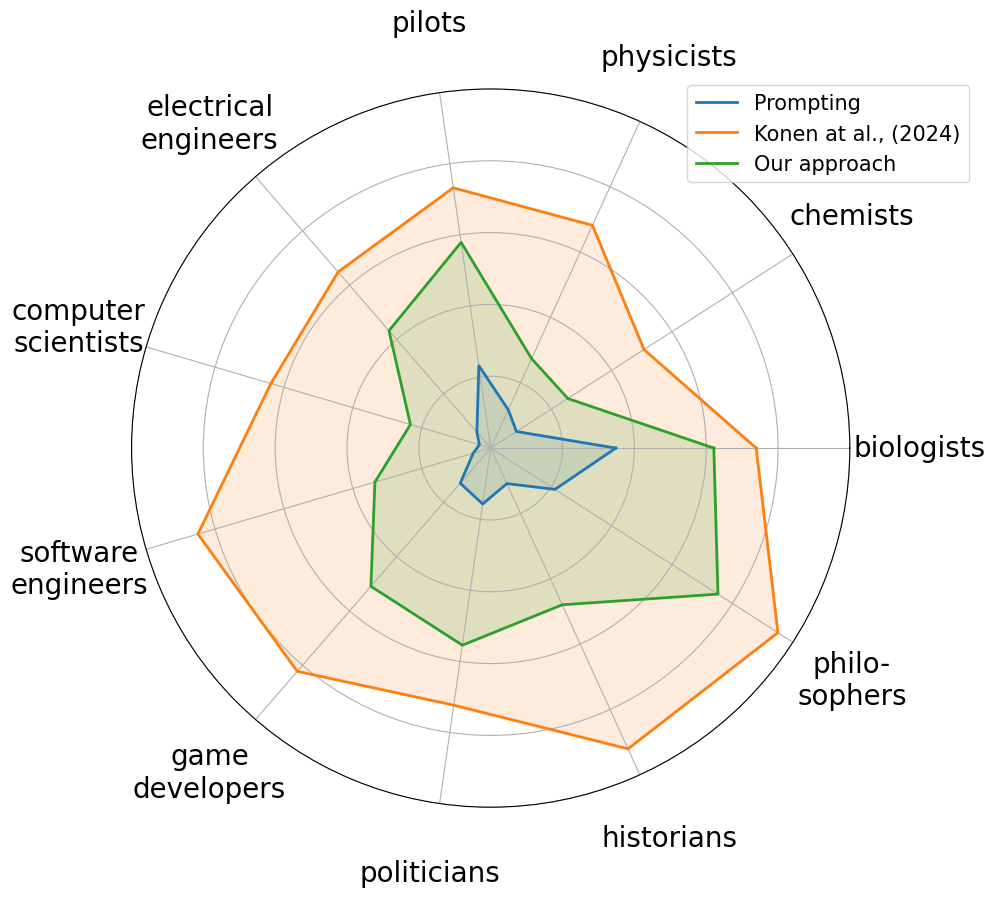

In [7]:
# Qwen (7B), eli5 questions

test_data_split = "eli5_test"
steering_result = np.load(f"results_qwen_old_prompt/np_steering_results_{test_data_split}_{database.file_name}.npy")
group_score_result = {}
for steering_type_index, steering_type in enumerate(steering_types_order):
    group_score_result[steering_type] = steering_result[STEERING_METRICS.index("group_score"), steering_type_index, :, :].mean(axis=1)

data_prompt_group = {
    "group": target_group_order,
    #"specificity": [0.225146,0.340344,0.0864221,0.0345097,0.0594238,0.13185,
    #                0.102762,0.22071,0.117932,0.155457,0.0532368],
    "specificity": group_score_result["prompt_group"]
}

data_activation_konen_group = {
    "group": target_group_order,
    #"specificity": [0.749719,0.751917,0.506144,0.646549,0.652524,0.819602,
    #                0.911818,0.956083,0.686102,0.717227,0.852239],
    "specificity": group_score_result["activation_konen_group"]
}

# difference activation vectors
data_activation_group_attribute_5 = {
    "group": target_group_order,
    #"specificity": [0.599423,0.614764,0.26546,0.228428,0.432005,0.511092,
    #                0.478587,0.757937,0.273103,0.546788,0.328839],
    "specificity": group_score_result["activation_group_attribute_5"]
}

# Convert to DataFrames
df_prompt = pd.DataFrame(data_prompt_group).set_index("group")
df_konen = pd.DataFrame(data_activation_konen_group).set_index("group")
df_attr5 = pd.DataFrame(data_activation_group_attribute_5).set_index("group")

df_prompt = df_prompt.loc[desired_group_order]
df_konen = df_konen.loc[desired_group_order]
df_attr5 = df_attr5.loc[desired_group_order]

groups = [GROUP_STEERING_NAMES[group] for group in desired_group_order]

# Extract scores in the new order
values_prompt = df_prompt["specificity"].tolist()
values_konen = df_konen["specificity"].tolist()
values_attr5 = df_attr5["specificity"].tolist()

# Close radar loop
values_prompt += values_prompt[:1]
values_konen += values_konen[:1]
values_attr5 += values_attr5[:1]

# Angle setup
N = len(groups)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

# -----------------------------------
# PLOT SPIDER GRAPH
# -----------------------------------
plt.figure(figsize=(10, 10))
ax = plt.subplot(111, polar=True)

ax.plot(angles, values_prompt, linewidth=2, label="Prompting")
ax.fill(angles, values_prompt, alpha=0.15)

ax.plot(angles, values_konen, linewidth=2, label="Konen at al., (2024)")
ax.fill(angles, values_konen, alpha=0.15)

ax.plot(angles, values_attr5, linewidth=2, label="Our approach")
ax.fill(angles, values_attr5, alpha=0.15)

# Labels in your custom order
ax.set_xticks(angles[:-1])
ax.set_xticklabels(groups, fontsize=20)
ax.tick_params(axis='x', pad=40)

ax.set_yticklabels([])
ax.set_ylim(0, 1)


#plt.title("Per-Group Performance: specificity by Approach", fontsize=16)
plt.legend(loc="upper right", bbox_to_anchor=(1.18, 1.02), fontsize=15)

plt.tight_layout()
plt.savefig("group-score-per-group-eli5.pdf", format="pdf", bbox_inches="tight")
plt.show()

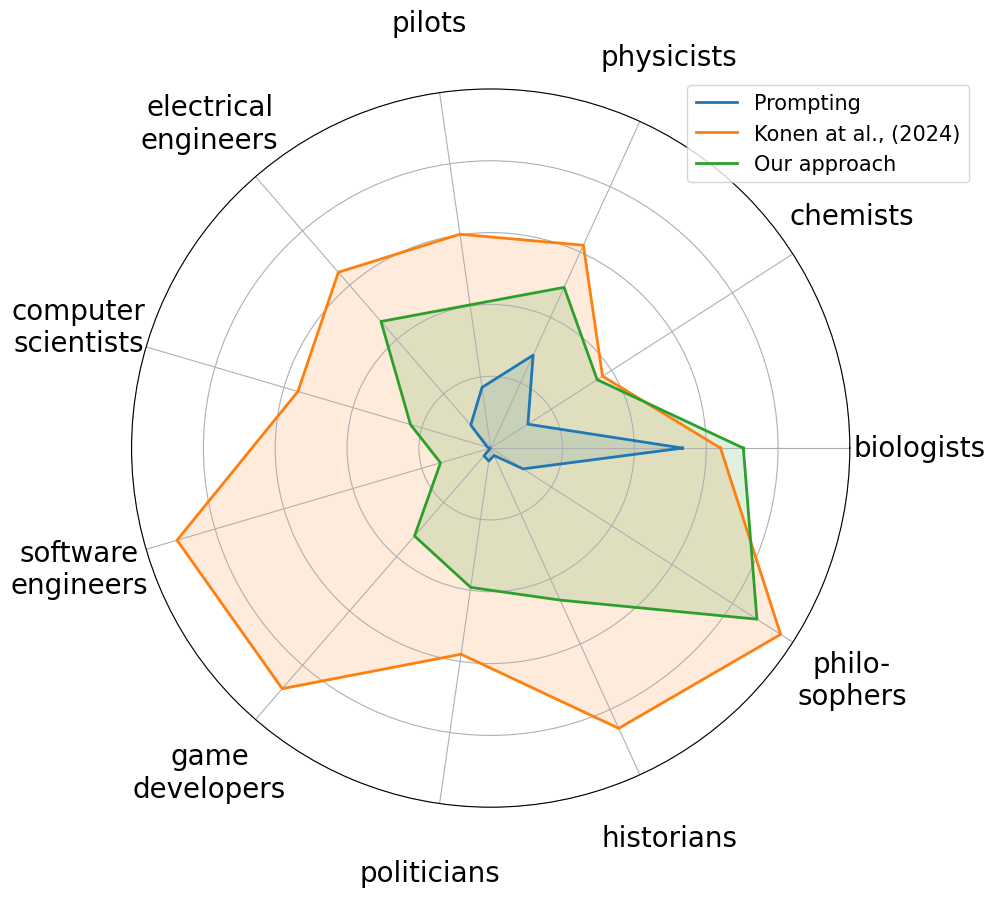

In [8]:
# Qwen (7B), science questions (Rooein et al., 2023)

test_data_split = "rooein_test"
steering_result = np.load(f"results_qwen_old_prompt/np_steering_results_{test_data_split}_{database.file_name}.npy")
group_score_result = {}
for steering_type_index, steering_type in enumerate(steering_types_order):
    group_score_result[steering_type] = steering_result[STEERING_METRICS.index("group_score"), steering_type_index, :, :].mean(axis=1)


data_prompt_group = {
    "group": target_group_order,
    #"specificity": [
    #    0.159439, 0.531541, 0.118136, 0.00282847, 0.0884999,
    #    0.018656, 0.018573, 0.101095, 0.297116, 0.0357006,
    #    0.000599115
    #]
    "specificity": group_score_result["prompt_group"]
}

data_activation_konen_group = {
    "group": target_group_order,
    #"specificity": [
    #    0.599813, 0.652571, 0.359343, 0.579036, 0.608848,
    #    0.896726, 0.853384, 0.962839, 0.630167, 0.569513,
    #    0.881173
    #]
    "specificity": group_score_result["activation_konen_group"]
}

data_activation_group_attribute_5 = {
    "group": target_group_order,
    #"specificity": [
    #    0.418095, 0.683419, 0.355507, 0.240202, 0.473413,
    #    0.340573, 0.482631, 0.898494, 0.489051, 0.393891,
    #    0.129873
    #]
    "specificity": group_score_result["activation_group_attribute_5"]
}

# Convert to DataFrames
df_prompt = pd.DataFrame(data_prompt_group).set_index("group")
df_konen = pd.DataFrame(data_activation_konen_group).set_index("group")
df_attr5 = pd.DataFrame(data_activation_group_attribute_5).set_index("group")

df_prompt = df_prompt.loc[desired_group_order]
df_konen = df_konen.loc[desired_group_order]
df_attr5 = df_attr5.loc[desired_group_order]

groups = [GROUP_STEERING_NAMES[group] for group in desired_group_order]

# Extract scores in the new order
values_prompt = df_prompt["specificity"].tolist()
values_konen = df_konen["specificity"].tolist()
values_attr5 = df_attr5["specificity"].tolist()

# Close radar loop
values_prompt += values_prompt[:1]
values_konen += values_konen[:1]
values_attr5 += values_attr5[:1]

# Angle setup
N = len(groups)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

# -----------------------------------
# PLOT SPIDER GRAPH
# -----------------------------------
plt.figure(figsize=(10, 10))
ax = plt.subplot(111, polar=True)

ax.plot(angles, values_prompt, linewidth=2, label="Prompting")
ax.fill(angles, values_prompt, alpha=0.15)

ax.plot(angles, values_konen, linewidth=2, label="Konen at al., (2024)")
ax.fill(angles, values_konen, alpha=0.15)

ax.plot(angles, values_attr5, linewidth=2, label="Our approach")
ax.fill(angles, values_attr5, alpha=0.15)

# Labels in your custom order
ax.set_xticks(angles[:-1])
ax.set_xticklabels(groups, fontsize=20)
ax.tick_params(axis='x', pad=40)

ax.set_yticklabels([])
ax.set_ylim(0, 1)


#plt.title("Per-Group Performance: specificity by Approach", fontsize=16)
plt.legend(loc="upper right", bbox_to_anchor=(1.18, 1.02), fontsize=15)

plt.tight_layout()
plt.savefig("group-score-per-group-rooein.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [17]:
def harmonic_means_two(criterion1, criterion2):
    hmeans = []
    for x1, x2 in zip(criterion1, criterion2):
        hmeans.append((2 * x1 * x2) / (x1 + x2))
    return hmeans

In [14]:
def harmonic_mean_two(criterion1, criterion2):
    hmean = (2 * criterion1 * criterion2) / (criterion1 + criterion2)
    return hmean

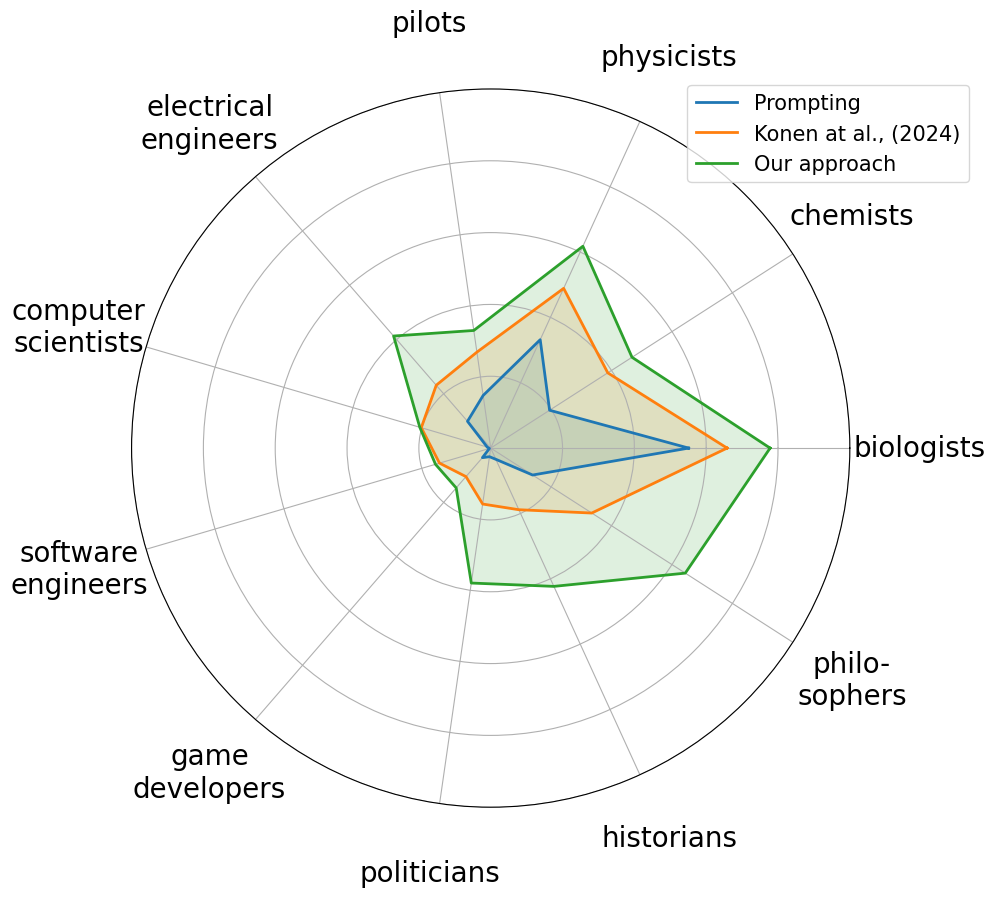

In [18]:
# Qwen (7B), science questions (Rooein et al., 2023)
test_data_split = "rooein_test"
steering_result = np.load(f"results_qwen_old_prompt/np_steering_results_{test_data_split}_{database.file_name}.npy")
group_score_result = {}
for steering_type_index, steering_type in enumerate(steering_types_order):
    group_score_result[steering_type] = steering_result[STEERING_METRICS.index("group_score"), steering_type_index, :, :]
with open(f"results_qwen_old_prompt/results_factscore_{database.file_name}.json", "r") as f:
    factscore_result = json.load(f)

hmean_result = {}
for steering_type in group_score_result:
    hmean_result[steering_type] = []
    for target_group, group_specificity in zip(target_group_order, group_score_result[steering_type]):
        group_indices = np.where(np.array(factscore_result[steering_type]["target_groups"]) == target_group)[0]
        group_factscore = np.array(factscore_result[steering_type]["factscores_cleaned"])[group_indices]
        assert len(group_specificity) == len(group_factscore)
        hmean_result[steering_type].append(np.mean(harmonic_means_two(group_specificity, group_factscore)))
        #hmean_result[steering_type].append(harmonic_mean_two(np.mean(group_specificity), np.mean(group_factscore)))
    
data_prompt_group = {
    "group": target_group_order,
    "hmean": hmean_result["prompt_group"]
}

data_activation_konen_group = {
    "group": target_group_order,
    "hmean": hmean_result["activation_konen_group"]
}

data_activation_group_attribute_5 = {
    "group": target_group_order,
    "hmean": hmean_result["activation_group_attribute_5"]
}
    
# Convert to DataFrames
df_prompt = pd.DataFrame(data_prompt_group).set_index("group")
df_konen = pd.DataFrame(data_activation_konen_group).set_index("group")
df_attr5 = pd.DataFrame(data_activation_group_attribute_5).set_index("group")

df_prompt = df_prompt.loc[desired_group_order]
df_konen = df_konen.loc[desired_group_order]
df_attr5 = df_attr5.loc[desired_group_order]

groups = [GROUP_STEERING_NAMES[group] for group in desired_group_order]

# Extract scores in the new order
values_prompt = df_prompt["hmean"].tolist()
values_konen = df_konen["hmean"].tolist()
values_attr5 = df_attr5["hmean"].tolist()

# Close radar loop
values_prompt += values_prompt[:1]
values_konen += values_konen[:1]
values_attr5 += values_attr5[:1]

# Angle setup
N = len(groups)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

# -----------------------------------
# PLOT SPIDER GRAPH
# -----------------------------------
plt.figure(figsize=(10, 10))
ax = plt.subplot(111, polar=True)

ax.plot(angles, values_prompt, linewidth=2, label="Prompting")
ax.fill(angles, values_prompt, alpha=0.15)

ax.plot(angles, values_konen, linewidth=2, label="Konen at al., (2024)")
ax.fill(angles, values_konen, alpha=0.15)

ax.plot(angles, values_attr5, linewidth=2, label="Our approach")
ax.fill(angles, values_attr5, alpha=0.15)

# Labels in your custom order
ax.set_xticks(angles[:-1])
ax.set_xticklabels(groups, fontsize=20)
ax.tick_params(axis='x', pad=40)

ax.set_yticklabels([])
ax.set_ylim(0, 0.5)


#plt.title("Per-Group Performance: specificity by Approach", fontsize=16)
plt.legend(loc="upper right", bbox_to_anchor=(1.18, 1.02), fontsize=15)

plt.tight_layout()
plt.savefig("hmean-per-group-rooein.pdf", format="pdf", bbox_inches="tight")
plt.show()